In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from  sklearn.datasets import fetch_california_housing
# load dataset
california=fetch_california_housing()
#printing keys
print("Dataset Keys:",california.keys())


Dataset Keys: dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])


In [4]:
#creating data frame
dataset=pd.DataFrame(california.data,columns=california.feature_names)
print(dataset.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


In [5]:
#adding dependent/target feature(price)
dataset['Price']=california.target
print(dataset.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  


In [6]:
#dividing into dependent and independent features
X=pd.DataFrame(california.data,columns=california.feature_names) #independent
Y=california.target #dependent

In [7]:
#train-test split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=42)


In [8]:
#Standardizing the dataset
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
#fit and transform training data ,only transform testing data
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

how to inverse transform data back to original values
original_X_train=scaler.inverse_transform(X_train)

In [9]:
#Model training(Linear Regression)
from sklearn.linear_model import LinearRegression
regression=LinearRegression()
regression.fit(X_train,Y_train)

LinearRegression()

In [11]:
#HYperparameter Tuning/model checking via Cross-validation
from sklearn.model_selection import cross_val_score
mse_scores=cross_val_score(regression,X_train,Y_train,scoring='neg_mean_squared_error',cv=5)
print("MSE Scores for each fold:",mse_scores)
print("Mean MSE score:",np.mean(mse_scores))

MSE Scores for each fold: [-0.54787556 -0.500835   -0.52045639 -0.51612252 -0.54883741]
Mean MSE score: -0.5268253746355748


In [12]:
# doing prediction on test data
reg_pred=regression.predict(X_test)
print("predicted values:",reg_pred)

predicted values: [0.72604907 1.76743383 2.71092161 ... 2.07465531 1.57371395 1.82744133]


<function matplotlib.pyplot.show(close=None, block=None)>

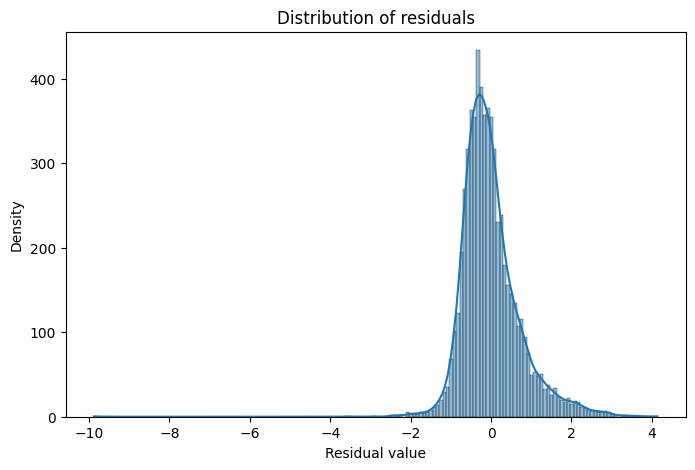

In [13]:
#visualizing the prediction performance (Residual analysis)
#plotting the difference betweeen truth and predictions using distribution plot
residuals=Y_test-reg_pred
plt.figure(figsize=(8,5))
sns.histplot(residuals,kde=True)
plt.title("Distribution of residuals")
plt.xlabel("Residual value")
plt.ylabel("Density")
plt.show

In [14]:
#performance metrics(R-squared Score)
from sklearn.metrics import r2_score
score=r2_score(Y_test,reg_pred)
print("R-squared Score:",score)

R-squared Score: 0.5957702326061664
